# captur de frutas

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

np.random.seed(42)

partidas = 1000
turnos = 100

sectores = [1, 2, 3, 4, 5]
frutas = ["manzana", "naranja", "uvas", "sandia"]
valores_frutas = {
    "manzana": 1,
    "naranja": 2,
    "uvas": 3,
    "sandia": 5
}
cantidades = [0, 1, 2, 3, 4]

# Probabilidad de obtener 0, 1, 2, 3 o 4 frutas en cada sector.
prob_cantidad = {
    1: [0.05, 0.15, 0.45, 0.25, 0.10],
    2: [0.10, 0.20, 0.30, 0.30, 0.10],
    3: [0.25, 0.35, 0.25, 0.10, 0.05],
    4: [0.05, 0.10, 0.20, 0.35, 0.30],
    5: [0.15, 0.15, 0.25, 0.25, 0.20]
}

# Orden de tipos: manzana, naranja, uvas, sandía.
prob_frutas = {
    1: [0.65, 0.20, 0.10, 0.05],
    2: [0.20, 0.40, 0.25, 0.15],
    3: [0.40, 0.30, 0.20, 0.10],
    4: [0.10, 0.15, 0.25, 0.50],
    5: [0.25, 0.25, 0.25, 0.25]
}

def entorno(sector):
    cantidad = np.random.choice(cantidades, p=prob_cantidad[sector])

    if cantidad == 0:
        return 0, []

    frutas_obtenidas = np.random.choice(
        frutas,
        size=cantidad,
        p=prob_frutas[sector]
    )

    recompensa = sum(valores_frutas[fruta] for fruta in frutas_obtenidas)

    return recompensa, frutas_obtenidas

In [2]:
valores = np.array([valores_frutas[fruta] for fruta in frutas])

recompensas_esperadas = {}

for sector in sectores:
    cantidad_media = np.dot(cantidades, prob_cantidad[sector])
    valor_medio_fruta = np.dot(valores, prob_frutas[sector])
    recompensas_esperadas[sector] = cantidad_media * valor_medio_fruta

mejor_accion = max(recompensas_esperadas, key=recompensas_esperadas.get)

print("Recompensa esperada por sector:")
for sector in sectores:
    print(f"Sector {sector}: {recompensas_esperadas[sector]:.4f}")

print(f"\nMejor sector: {mejor_accion}")

Recompensa esperada por sector:
Sector 1: 3.5200
Sector 2: 5.2500
Sector 3: 2.8350
Sector 4: 10.0375
Sector 5: 6.0500

Mejor sector: 4


## accion valor


In [3]:
epsilons = [0, 0.01, 0.1]
recompensas_medias = np.zeros((len(epsilons), turnos))
acciones_optimas = np.zeros((len(epsilons), turnos))

for ej in range(partidas):
    for i, e in enumerate(epsilons):
        Q = {k: 0 for k in sectores}
        acciones = {k: 0 for k in sectores}
        recompensas = {k: 0 for k in sectores}

        for exp in range(turnos):
            # elegir acción
            if np.random.uniform(0, 1) < e:
                # acción aleatoria
                a = np.random.randint(5) + 1
            else:
                # acción con mayor valor
                maxQ = -100
                for j in sectores:
                    if Q[j] > maxQ:
                        maxQ = Q[j]
                        a = j

            recompensa, frutas_obtenidas = entorno(a)
            acciones[a] += 1
            recompensas[a] += recompensa
            Q[a] = recompensas[a] / acciones[a]

            recompensas_medias[i][exp] += recompensa
            acciones_optimas[i][exp] += (a == mejor_accion)

recompensas_medias /= partidas
acciones_optimas /= partidas

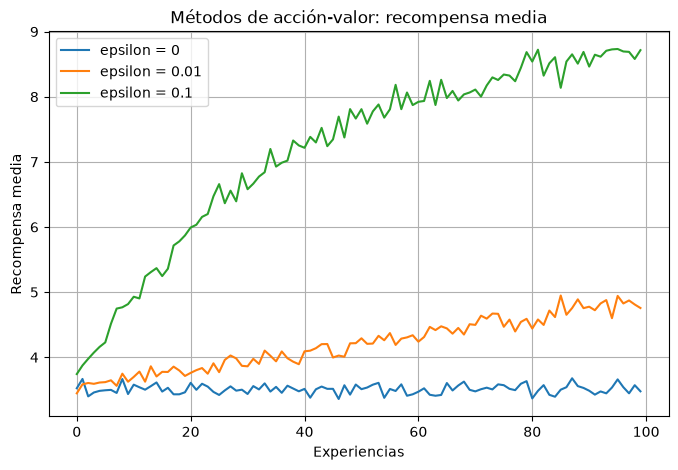

In [4]:
plt.figure(figsize=(8, 5))
for i, e in enumerate(epsilons):
    plt.plot(recompensas_medias[i], label=f'epsilon = {e}')
plt.legend()
plt.grid(True)
plt.xlabel('Experiencias')
plt.ylabel('Recompensa media')
plt.title('Métodos de acción-valor: recompensa media')
plt.show()

## implementacion incremental

In [5]:
alpha = 0.95
epsilons = [0, 0.01, 0.1]
recompensas_medias = np.zeros((len(epsilons), turnos))
acciones_optimas = np.zeros((len(epsilons), turnos))

for ej in range(partidas):
    for i, e in enumerate(epsilons):
        Q = {k: 0 for k in sectores}

        for exp in range(turnos):
            # elegir acción
            if np.random.uniform(0, 1) < e:
                # acción aleatoria
                a = np.random.randint(5) + 1
            else:
                # acción con mayor valor
                maxQ = -100
                for j in sectores:
                    if Q[j] > maxQ:
                        maxQ = Q[j]
                        a = j

            recompensa, frutas_obtenidas = entorno(a)

            # actualización incremental
            Q[a] += alpha * (recompensa - Q[a])

            recompensas_medias[i][exp] += recompensa
            acciones_optimas[i][exp] += (a == mejor_accion)

recompensas_medias /= partidas
acciones_optimas /= partidas

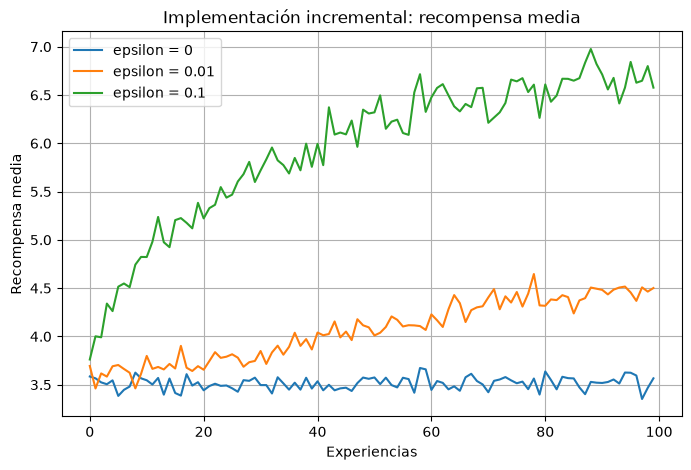

In [6]:
plt.figure(figsize=(8, 5))
for i, e in enumerate(epsilons):
    plt.plot(recompensas_medias[i], label=f'epsilon = {e}')
plt.legend()
plt.grid(True)
plt.xlabel('Experiencias')
plt.ylabel('Recompensa media')
plt.title('Implementación incremental: recompensa media')
plt.show()

## valores iniciales optimos

In [7]:
alpha = 0.5
epsilons = [0, 0.1]
recompensas_medias = np.zeros((len(epsilons), turnos))
acciones_optimas = np.zeros((len(epsilons), turnos))

for ej in range(partidas):
    for i, e in enumerate(epsilons):
        Q = {k: 0 for k in sectores}

        # inicializamos a valores altos si el agente es greedy
        if e == 0:
            Q = {k: 20 for k in sectores}

        for exp in range(turnos):
            # elegir acción
            if np.random.uniform(0, 1) < e:
                # acción aleatoria
                a = np.random.randint(5) + 1
            else:
                # acción con mayor valor
                maxQ = -100
                for j in sectores:
                    if Q[j] > maxQ:
                        maxQ = Q[j]
                        a = j

            recompensa, frutas_obtenidas = entorno(a)
            Q[a] += alpha * (recompensa - Q[a])

            recompensas_medias[i][exp] += recompensa
            acciones_optimas[i][exp] += (a == mejor_accion)

recompensas_medias /= partidas
acciones_optimas /= partidas

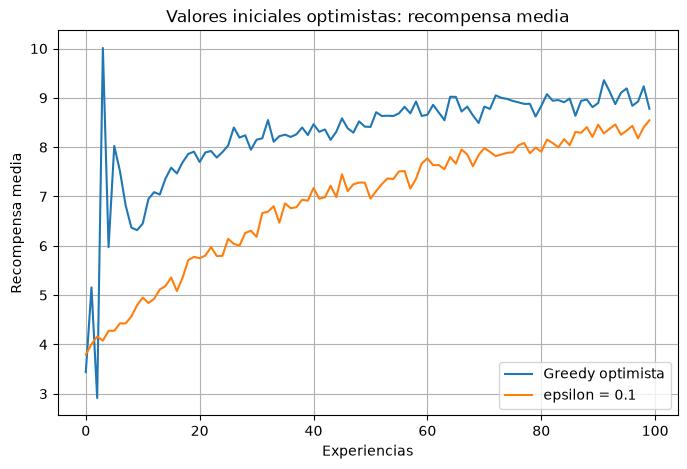

In [8]:
plt.figure(figsize=(8, 5))
for i, e in enumerate(epsilons):
    etiqueta = 'Greedy optimista' if e == 0 else f'epsilon = {e}'
    plt.plot(recompensas_medias[i], label=etiqueta)
plt.legend()
plt.grid(True)
plt.xlabel('Experiencias')
plt.ylabel('Recompensa media')
plt.title('Valores iniciales optimistas: recompensa media')
plt.show()